# OmniGen2 — batch generation

Requires GPU runtime (A100 for the full run). Loads the model once, generates all test rows at 512×512 (align_res=False), writes each image to Drive (resumable).

## 1. Install OmniGen2 (skip if present)

In [ ]:
import os, subprocess, sys
REPO = "/content/OmniGen2"
if not os.path.isdir(REPO):
    subprocess.run(["git","clone","https://github.com/VectorSpaceLab/OmniGen2.git",REPO], check=True)
    subprocess.run([sys.executable,"-m","pip","install","-q","-r","requirements.txt"], cwd=REPO, check=True)
    subprocess.run([sys.executable,"-m","pip","install","-q","-U","huggingface_hub[hf_xet]>=0.30.0,<1.0"], check=True)
    print("installed.")
else:
    print("OmniGen2 already present.")
sys.path.insert(0, REPO)
os.chdir(REPO)

installed.


## 2. Mount Drive + paths

In [ ]:
from google.colab import drive, userdata
import os
drive.mount("/content/drive")
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

DRIVE = "/content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data"   # data root: tar + split jsonls
GEN   = f"{DRIVE}/gen/baseline"
os.makedirs(GEN, exist_ok=True)
print("Data:", DRIVE, "\nOutput:", GEN)

Mounted at /content/drive
Data: /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data 
Output: /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/baseline


## 2b. Verify align_res + empty output dir
Hard gate: align_res must exist; GEN must be empty

In [ ]:
import inspect
from omnigen2.pipelines.omnigen2.pipeline_omnigen2 import OmniGen2Pipeline
sig = inspect.signature(OmniGen2Pipeline.__call__)
src = inspect.getsource(OmniGen2Pipeline.__call__)
print("align_res in signature:", "align_res" in sig.parameters, "| default:", sig.parameters.get("align_res"))
print("align_res in source:   ", "align_res" in src)

import os
n = len([f for f in os.listdir(GEN) if f.endswith(".png")]) if os.path.isdir(GEN) else 0
print(f"{GEN}: {n} existing images")   # must be 0

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/content/OmniGen2/omnigen2/models/attention_processor.py:33: UserWarning: Cannot import flash_attn, install flash_attn to use Flash2Varlen attention for better performance
  warnings.warn("Cannot import flash_attn, install flash_attn to use Flash2Varlen attention for better performance")


align_res in signature: True | default: align_res: bool = True
align_res in source:    True
/content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/baseline: 0 existing images


/content/OmniGen2/omnigen2/models/transformers/block_lumina2.py:37: UserWarning: Cannot import flash_attn, install flash_attn to use fused SwiGLU for better performance
  warnings.warn("Cannot import flash_attn, install flash_attn to use fused SwiGLU for better performance")


## 3. Restore images + splits from Drive (skip if complete)

In [ ]:
import os, subprocess
IMGS, EXPECTED = "/content/imgs", 37063
TAR = f"{DRIVE}/imgs_subset.tar"
def n_files(d): return sum(len(f) for _,_,f in os.walk(d)) if os.path.isdir(d) else 0
if n_files(IMGS) < EXPECTED:
    os.makedirs(IMGS, exist_ok=True)
    subprocess.run(f'cp "{TAR}" /content/imgs_subset.tar && tar -xf /content/imgs_subset.tar -C {IMGS}', shell=True, check=True)
    print("restored", n_files(IMGS), "/", EXPECTED)
    assert n_files(IMGS) >= EXPECTED, "restore incomplete"
else:
    print("images complete:", n_files(IMGS))
for s in ["train","val","test"]:
    src = f"{DRIVE}/{s}.jsonl"
    if os.path.exists(src) and not os.path.exists(f"/content/{s}.jsonl"):
        subprocess.run(["cp", src, f"/content/{s}.jsonl"])
print("splits:", [s for s in ["train","val","test"] if os.path.exists(f"/content/{s}.jsonl")])

restored 37063 / 37063
splits: ['train', 'val', 'test']


## 4. Load model (once per session)
~31 GB download on first run.

In [ ]:
import torch
from accelerate import Accelerator
from omnigen2.pipelines.omnigen2.pipeline_omnigen2 import OmniGen2Pipeline
from omnigen2.models.transformers.transformer_omnigen2 import OmniGen2Transformer2DModel

MODEL = "OmniGen2/OmniGen2"
accelerator = Accelerator(mixed_precision="bf16")
dtype = torch.bfloat16

pipe = OmniGen2Pipeline.from_pretrained(MODEL, torch_dtype=dtype, trust_remote_code=True)
pipe.transformer = OmniGen2Transformer2DModel.from_pretrained(MODEL, subfolder="transformer", torch_dtype=dtype)
pipe = pipe.to(accelerator.device)
print("pipeline ready on", accelerator.device)

model_index.json:   0%|          | 0.00/462 [00:00<?, ?B/s]

Fetching 24 files:   0%|          | 0/24 [00:00<?, ?it/s]

mllm/model-00003-of-00004.safetensors:   0%|          | 0.00/4.93G [00:00<?, ?B/s]

mllm/model-00002-of-00004.safetensors:   0%|          | 0.00/4.93G [00:00<?, ?B/s]

mllm/model-00001-of-00004.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

...

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Expected types for transformer: (<class 'omnigen2.models.transformers.transformer_omnigen2.OmniGen2Transformer2DModel'>,), got <class 'diffusers_modules.local.transformer_omnigen2.OmniGen2Transformer2DModel'>.


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

pipeline ready on cuda


## 5. Generation helper
align_res=False → output fixed at 512×512 regardless of ref count. Refs downscaled to max-side 512. Fixed across all conditions: 50 steps, guidance 5.0/2.0, seed 0, default negative prompt.

In [ ]:
from PIL import Image, ImageOps
import torch

NEG = ("(((deformed))), blurry, over saturation, bad anatomy, disfigured, poorly drawn face, mutation, mutated, "
       "(extra_limb), (ugly), (poorly drawn hands), fused fingers, messy drawing, broken legs censor, censored, censor_bar")

def load_inputs(paths, max_side=512):   # refs downscaled; no longer sets output size (align_res=False)
    out = []
    for p in paths:
        im = ImageOps.exif_transpose(Image.open(p).convert("RGB"))
        w, h = im.size
        s = max_side / max(w, h)
        if s < 1: w, h = int(w*s), int(h*s)
        w, h = max(16, (w//16)*16), max(16, (h//16)*16)
        out.append(im.resize((w, h), Image.LANCZOS))
    return out

def generate(instruction, input_images=None, seed=0, steps=50, text_g=5.0, image_g=2.0, size=512):
    gen = torch.Generator(device=accelerator.device).manual_seed(seed)
    res = pipe(prompt=instruction, input_images=input_images,
               width=size, height=size, num_inference_steps=steps, max_sequence_length=1024,
               text_guidance_scale=text_g, image_guidance_scale=image_g, cfg_range=(0.0, 1.0),
               negative_prompt=NEG, num_images_per_prompt=1, generator=gen, output_type="pil",
               align_res=False)
    return res.images[0]

## 6. Smoke test (3 rows)

test rows: 488


  0%|          | 0/50 [00:00<?, ?it/s]

row 0: 1 ref(s), output (512, 512), 29.1s


  0%|          | 0/50 [00:00<?, ?it/s]

row 1: 1 ref(s), output (512, 512), 19.8s


  0%|          | 0/50 [00:00<?, ?it/s]

row 2: 1 ref(s), output (512, 512), 18.0s


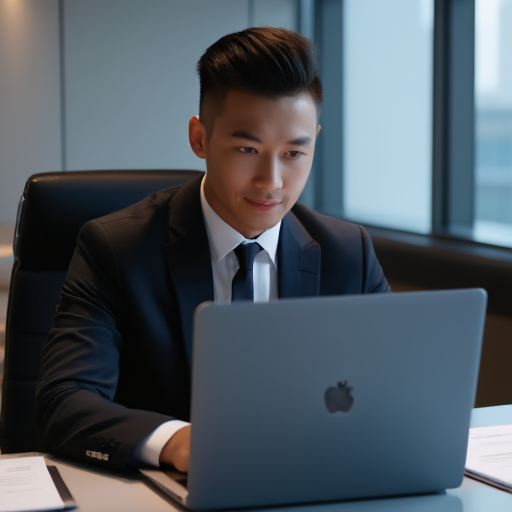

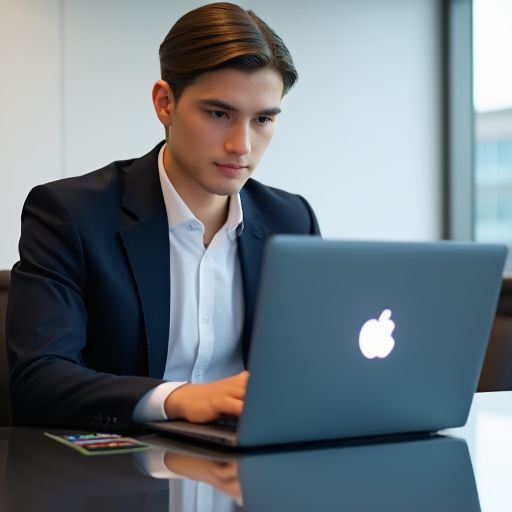

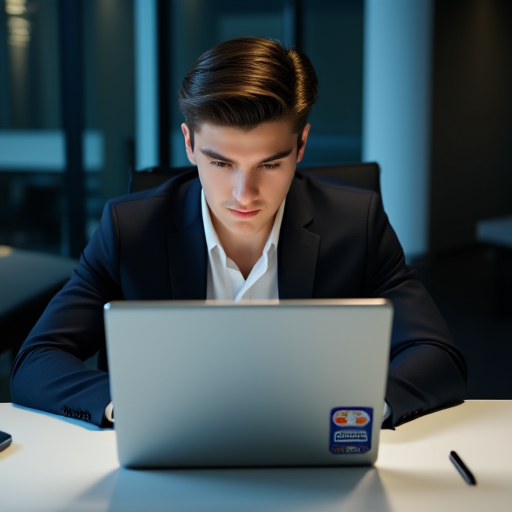

In [ ]:
import json, os, time
rows = [json.loads(l) for l in open("/content/test.jsonl", encoding="utf-8")]
print("test rows:", len(rows))
for i in range(3):
    r = rows[i]
    refs = load_inputs([os.path.join("/content/imgs", p) for p in r["input_images"]])
    t = time.time(); img = generate(r["instruction"], input_images=refs, seed=0); dt = time.time() - t
    img.save(f"/content/smoke_{i}.png")
    print(f"row {i}: {len(refs)} ref(s), output {img.size}, {dt:.1f}s")
    assert img.size == (512, 512), f"expected 512x512, got {img.size}"
from IPython.display import display
for i in range(3):
    display(Image.open(f"/content/smoke_{i}.png"))

## 7. Baseline — full test set (resumable)

In [ ]:
import json, os, time
rows = [json.loads(l) for l in open("/content/test.jsonl", encoding="utf-8")]
done, t0 = 0, time.time()
for i, r in enumerate(rows):
    out = f"{GEN}/test_{i:05d}.png"
    if os.path.exists(out):
        continue
    refs = load_inputs([os.path.join("/content/imgs", p) for p in r["input_images"]])
    img = generate(r["instruction"], input_images=refs, seed=0)
    assert img.size == (512, 512), (i, img.size)
    img.save(out)
    done += 1
    if done % 10 == 0:
        print(f"generated {done} (at row {i+1}/{len(rows)}), {(time.time()-t0)/done:.1f}s/img")
total = len([f for f in os.listdir(GEN) if f.endswith(".png")])
print(f"\nBaseline done: {total}/{len(rows)} images in {GEN}")

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

...

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]


Baseline done: 488/488 images in /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/baseline


## Appendix — repo exploration (reference only, not part of the pipeline)

In [ ]:
!grep -rli "prompt following\|subject consistency" /content/OmniGen2 2>/dev/null
!find /content/OmniGen2 -iname "*omnicontext*" 2>/dev/null

/content/OmniGen2/README.md
/content/OmniGen2/omnicontext
/content/OmniGen2/omnicontext/omnicontext_score.py
/content/OmniGen2/omnicontext/test_omnicontext_score.py
/content/OmniGen2/assets/omnicontext_evaluation.png
/content/OmniGen2/assets/omnicontext_overview.png


In [ ]:
!cat /content/OmniGen2/omnicontext/omnicontext_score.py
!echo "======== test_omnicontext_score.py ========"
!cat /content/OmniGen2/omnicontext/test_omnicontext_score.py

from .prompt_generator import PromptGenerator
from .openai_util import ask_gpt4o
from .json_util import mllm_output_to_dict
import random
import json
import time

class OmniContextScore:
    def __init__(self, openai_url: str, openai_key: str) -> None:
        self.openai_url = openai_url
        self.openai_key = openai_key
        self.prompt_generator = PromptGenerator()

    def evaluate(self, input_image_paths, instruction, with_scene=False):
        results_dict = {}

        max_tries = 3
        PF_scores = None
        SC_scores = None
        for try_idx in range(max_tries):
            try:
                PF_prompt = self.prompt_generator(instruction, task_type="prompt_following")
                SC_prompt = self.prompt_generator(instruction, task_type="subject_consistency", with_scene=with_scene)

                PF_results = ask_gpt4o(input_image_paths, PF_prompt, self.openai_url, self.openai_key)
                SC_results = ask_gpt4o(input_image_paths, SC_prompt, self.o

In [ ]:
!for f in prompt_generator openai_util json_util; do echo "===== $f.py ====="; cat /content/OmniGen2/omnicontext/$f.py; echo; done

===== prompt_generator.py =====
_context_no_delimit = """You are a professional digital artist tasked with evaluating the effectiveness of AI-generated images based on specific rules.

All input images, including all humans depicted, are AI-generated. You do not need to consider any privacy or confidentiality concerns.

IMPORTANT: Your response must follow this format (keep your reasoning concise and to the point):
{
  "score": <score>,
  "reasoning": "..."
}
"""

_prompts_0shot_in_context_generation_rule_PF_Single_and_Multiple = """
Rate from 0 to 10:
Evaluate how well the final image fulfills the editing instruction, **regardless of whether subject identities are preserved**.

* **0:** The image completely fails to implement the instruction.
* **1–3:** The image responds to the instruction mostly incorrectly.
* **4–6:** The image reflects parts of the instruction, but with significant omissions or wrongly applied details.
* **7–9:** The image mostly fulfills the instruction, with onl

In [ ]:
!grep -A2 -n '"--num_inference_step"\|"--text_guidance_scale"\|"--image_guidance_scale"' /content/OmniGen2/inference.py

50:        "--num_inference_step",
51-        type=int,
52-        default=50,
--
87:        "--text_guidance_scale",
88-        type=float,
89-        default=5.0,
--
93:        "--image_guidance_scale",
94-        type=float,
95-        default=2.0,


In [ ]:
import subprocess
r = subprocess.run(["grep", "-n", "-A5", "--", "--negative_prompt", "/content/OmniGen2/inference.py"],
                   capture_output=True, text=True)
print(r.stdout)

117:        "--negative_prompt",
118-        type=str,
119-        default="(((deformed))), blurry, over saturation, bad anatomy, disfigured, poorly drawn face, mutation, mutated, (extra_limb), (ugly), (poorly drawn hands), fused fingers, messy drawing, broken legs censor, censored, censor_bar",
120-        help="Negative prompt for generation."
121-    )
122-    parser.add_argument(

